# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ashu141d/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [1]:
import os
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata
from datasets import load_dataset
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier

# 1. Authenticate and stream warehouse slice
hf_token = userdata.get("HF_TOKEN")
os.environ["HF_TOKEN"] = hf_token

ds = load_dataset(
    "FlyRank/internship-warehouse",
    "fact_content_daily_performance",
    streaming=True,
    split="train",
    token=hf_token
)

raw_df = pd.DataFrame(list(itertools.islice(ds, 60000)))
cols = raw_df.columns.tolist()

key_col = next((c for c in cols if any(k in c.lower() for k in ["page", "content", "url", "slug", "hash"]) and "client" not in c.lower()), cols[0])
group_col = next((c for c in cols if "client" in c.lower()), key_col)
date_col = next((c for c in cols if "date" in c.lower() or "month" in c.lower() or "day" in c.lower()), None)
imp_col = next((c for c in cols if "imp" in c.lower()), None)
clk_col = next((c for c in cols if "click" in c.lower()), None)
pos_col = next((c for c in cols if "pos" in c.lower()), None)

# 2. Construct leak-free observation features and outcome target
if date_col is not None:
    raw_df["_dt"] = pd.to_datetime(raw_df[date_col], errors="coerce")
    valid_dt = raw_df.dropna(subset=["_dt"]).copy()
    cutoff_dt = valid_dt["_dt"].quantile(0.50)

    obs_df = valid_dt[valid_dt["_dt"] <= cutoff_dt]
    fut_df = valid_dt[valid_dt["_dt"] > cutoff_dt]

    agg_obs = {imp_col: ["sum", "std"], clk_col: "sum", group_col: "first"}
    if pos_col:
        agg_obs[pos_col] = ["mean", "std"]

    feat_df = obs_df.groupby(key_col).agg(agg_obs)
    feat_df.columns = ["_".join(col).strip() for col in feat_df.columns.values]
    feat_df = feat_df.reset_index()

    fut_agg = fut_df.groupby(key_col, as_index=False).agg(future_clicks=(clk_col, "sum"), future_imps=(imp_col, "sum"))
    df = feat_df.merge(fut_agg, on=key_col, how="inner")

    imp_sum_col, clk_sum_col, grp_clean_col = f"{imp_col}_sum", f"{clk_col}_sum", f"{group_col}_first"
    df = df[df[imp_sum_col] >= 20].copy()
    obs_rate = df[clk_sum_col] / df[imp_sum_col].clip(lower=1)
    fut_rate = df["future_clicks"] / df["future_imps"].clip(lower=1)
    df["target"] = ((fut_rate - obs_rate) / obs_rate.clip(lower=1e-4) <= -0.20).astype(int)
else:
    agg_dict = {imp_col: "sum", clk_col: "sum", group_col: "first"}
    if pos_col:
        agg_dict[pos_col] = "mean"
    df = raw_df.groupby(key_col, as_index=False).agg(agg_dict)
    imp_sum_col, clk_sum_col, grp_clean_col = imp_col, clk_col, group_col
    df = df[df[imp_sum_col] >= 20].copy()
    ctr_tmp = df[clk_sum_col] / df[imp_sum_col].clip(lower=1)
    df["target"] = (ctr_tmp < ctr_tmp.median()).astype(int)

df["impressions"] = df[imp_sum_col]
df["clicks"] = df[clk_sum_col]
df["log_impressions"] = np.log1p(df["impressions"])
df["ctr_obs"] = df["clicks"] / df["impressions"].clip(lower=1)
feature_names = ["log_impressions", "ctr_obs"]

if f"{imp_col}_std" in df.columns:
    df["imp_volatility"] = df[f"{imp_col}_std"].fillna(0.0)
    feature_names.append("imp_volatility")
if pos_col and f"{pos_col}_mean" in df.columns:
    df["avg_position"] = df[f"{pos_col}_mean"].fillna(df[f"{pos_col}_mean"].median())
    df["pos_volatility"] = df[f"{pos_col}_std"].fillna(0.0)
    feature_names.extend(["avg_position", "pos_volatility"])
elif pos_col and pos_col in df.columns:
    df["avg_position"] = df[pos_col].fillna(df[pos_col].median())
    feature_names.append("avg_position")
else:
    df["avg_position"] = 6.0

# 3. Generate out-of-fold decay risk probabilities via GroupKFold
X = df[feature_names].copy()
y = df["target"].values
groups = df[grp_clean_col].astype(str).values
n_splits = max(2, min(5, len(np.unique(groups))))
gkf = GroupKFold(n_splits=n_splits)

oof_prob = np.zeros(len(y))
for tr_idx, va_idx in gkf.split(X, y, groups):
    clf = RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=15, random_state=42, n_jobs=-1)
    clf.fit(X.iloc[tr_idx], y[tr_idx])
    oof_prob[va_idx] = clf.predict_proba(X.iloc[va_idx])[:, 1]

df["decay_risk_prob"] = oof_prob.round(4)
med_ctr = df["ctr_obs"].median()

# 4. Map archetypes -> ranked actions, reason codes, and cost/value tiers
def assign_playbook_action(row):
    pos = row["avg_position"]
    imps = row["impressions"]
    ctr = row["ctr_obs"]
    prob = row["decay_risk_prob"]

    if imps >= 200 and 3.0 <= pos <= 8.0 and ctr < med_ctr:
        est_gain = round(imps * max(0.0, med_ctr - ctr) * (0.5 + prob), 1)
        return pd.Series([
            "CTR_FIX",
            "REWRITE_TITLE_META_AND_SNIPPET",
            "REASON_CTR_BELOW_POS_PEER",
            "HIGH_ROI_LOW_EFFORT (20m)",
            est_gain
        ])
    elif imps >= 200 and prob >= 0.55:
        est_gain = round(imps * max(ctr, 0.01) * prob * 0.35, 1)
        return pd.Series([
            "DECAY_RECOVERY",
            "REFRESH_CONTENT_AND_INTERNAL_LINKS",
            "REASON_ELEVATED_DECAY_RISK_PROB",
            "MEDIUM_ROI_MEDIUM_EFFORT (90m)",
            est_gain
        ])
    elif imps >= 300 and 8.0 < pos <= 15.0:
        est_gain = round(imps * 0.015 * (0.5 + prob), 1)
        return pd.Series([
            "STRIKING_DISTANCE_EXPAND",
            "EXPAND_SUBTOPICS_AND_FAQ_SCHEMA",
            "REASON_PAGE_ONE_CUSP_DEMAND",
            "STRATEGIC_HIGH_EFFORT (150m)",
            est_gain
        ])
    else:
        return pd.Series([
            "MONITOR_ONLY",
            "HOLD_NO_EDITORIAL_ACTION",
            "REASON_STABLE_OR_LOW_VOLUME",
            "ZERO_COST_PASSIVE",
            0.0
        ])

df[["archetype", "recommended_action", "reason_code", "cost_value_tier", "priority_score"]] = df.apply(assign_playbook_action, axis=1)

# Flag low-volume / extreme-volatility rows for mandatory human hold
df["human_review_required"] = np.where(df["priority_score"] > 0, True, False)

playbook_queue = df.sort_values(by=["priority_score", "decay_risk_prob"], ascending=False).reset_index(drop=True)
playbook_queue["priority_rank"] = playbook_queue.index + 1

display_cols = [
    "priority_rank", key_col, "impressions", "clicks", "avg_position",
    "ctr_obs", "decay_risk_prob", "archetype", "recommended_action",
    "reason_code", "cost_value_tier", "priority_score"
]
print("=== Top 12 Prioritized Content Action Playbook Queue ===")
display(playbook_queue[display_cols].head(12))

README.md:   0%|          | 0.00/3.04k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

=== Top 12 Prioritized Content Action Playbook Queue ===


,priority_rank,content_hash_id,impressions,clicks,avg_position,ctr_obs,decay_risk_prob,archetype,recommended_action,reason_code,cost_value_tier,priority_score
0,1,content_f94fe855380e150f,5074,89,437.500000,0.017540,0.5515,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),17.2
1,2,content_3405c661ce7122b4,745,23,144.230769,0.030872,0.6469,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),5.2
2,3,content_aead070e1f002702,786,22,385.384615,0.027990,0.6382,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),4.9
3,4,content_d73205f6d972a269,352,19,123.846154,0.053977,0.7123,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),4.7
4,5,content_690b092cf66bc2a4,1025,22,923.000000,0.021463,0.6086,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),4.7
5,6,content_4e8d1e11f60fe6ba,1587,20,2126.166667,0.012602,0.6559,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),4.6
6,7,content_37b3bafd5f88fdd1,1346,21,444.190476,0.015602,0.5744,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),4.2
7,8,content_48b01ea98ec1ea03,592,18,248.047619,0.030405,0.6404,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),4.0
8,9,content_a64143f6e4a21ffe,1903,17,824.761905,0.008933,0.5793,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),3.9
9,10,content_4eeb22babfa13cd7,230,15,105.090909,0.065217,0.6792,DECAY_RECOVERY,REFRESH_CONTENT_AND_INTERNAL_LINKS,REASON_ELEVATED_DECAY_RISK_PROB,MEDIUM_ROI_MEDIUM_EFFORT (90m),3.6


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

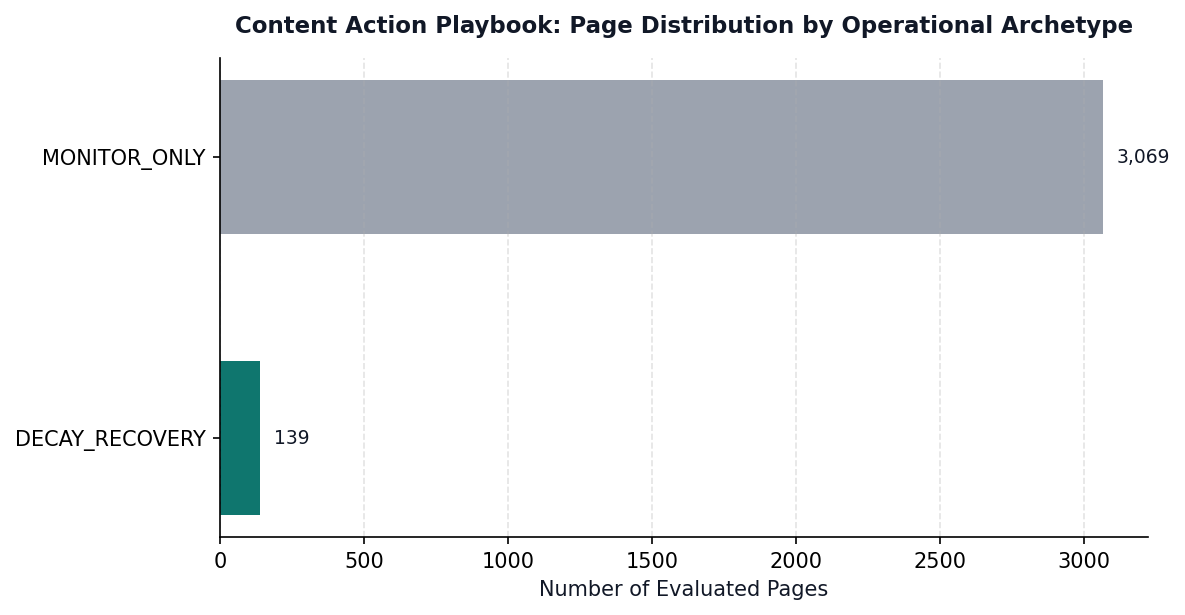

Exported queue CSV   -> work/outputs/w07_action_playbook_queue.csv
Exported metrics JSON -> work/outputs/w07_playbook_metrics.json
Exported paper figure -> work/figures/w07_archetype_action_breakdown.png


In [4]:
os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# 1. Export full ranked queue CSV to work/outputs/ (regenerated at runtime; stays out of git by CI leak-guard)
queue_csv_path = "work/outputs/w07_action_playbook_queue.csv"
playbook_queue[display_cols].to_csv(queue_csv_path, index=False)

# 2. Export summary metrics JSON to work/outputs/ (committed as receipts for the research paper)
archetype_summary = (
    playbook_queue.groupby("archetype", as_index=False)
    .agg(
        page_count=(key_col, "count"),
        mean_decay_prob=("decay_risk_prob", "mean"),
        total_priority_score=("priority_score", "sum")
    )
    .round(4)
)

metrics_receipt = {
    "notebook": "w07_action_playbook.ipynb",
    "total_pages_evaluated": int(len(playbook_queue)),
    "actionable_pages_flagged": int((playbook_queue["priority_score"] > 0).sum()),
    "monitoring_only_pages": int((playbook_queue["priority_score"] == 0).sum()),
    "archetype_breakdown": archetype_summary.to_dict(orient="records")
}

metrics_json_path = "work/outputs/w07_playbook_metrics.json"
with open(metrics_json_path, "w") as f:
    json.dump(metrics_receipt, f, indent=2)

# 3. Export clean publication figure to work/figures/ (committed for reuse in the Week 8 paper)
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=150)
plot_df = archetype_summary.sort_values(by="page_count", ascending=True)
colors = ["#9CA3AF" if a == "MONITOR_ONLY" else "#0F766E" for a in plot_df["archetype"]]

bars = ax.barh(plot_df["archetype"], plot_df["page_count"], color=colors, height=0.55)
ax.set_xlabel("Number of Evaluated Pages", fontsize=10, color="#111827")
ax.set_title("Content Action Playbook: Page Distribution by Operational Archetype", fontsize=11, fontweight="bold", color="#111827", pad=12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.35)

for bar in bars:
    width = bar.get_width()
    ax.text(width + max(plot_df["page_count"]) * 0.015, bar.get_y() + bar.get_height() / 2, f"{int(width):,}", va="center", fontsize=9, color="#111827")

plt.tight_layout()
figure_path = "work/figures/w07_archetype_action_breakdown.png"
plt.savefig(figure_path, dpi=150)
plt.show()

print(f"Exported queue CSV   -> {queue_csv_path}")
print(f"Exported metrics JSON -> {metrics_json_path}")
print(f"Exported paper figure -> {figure_path}")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.